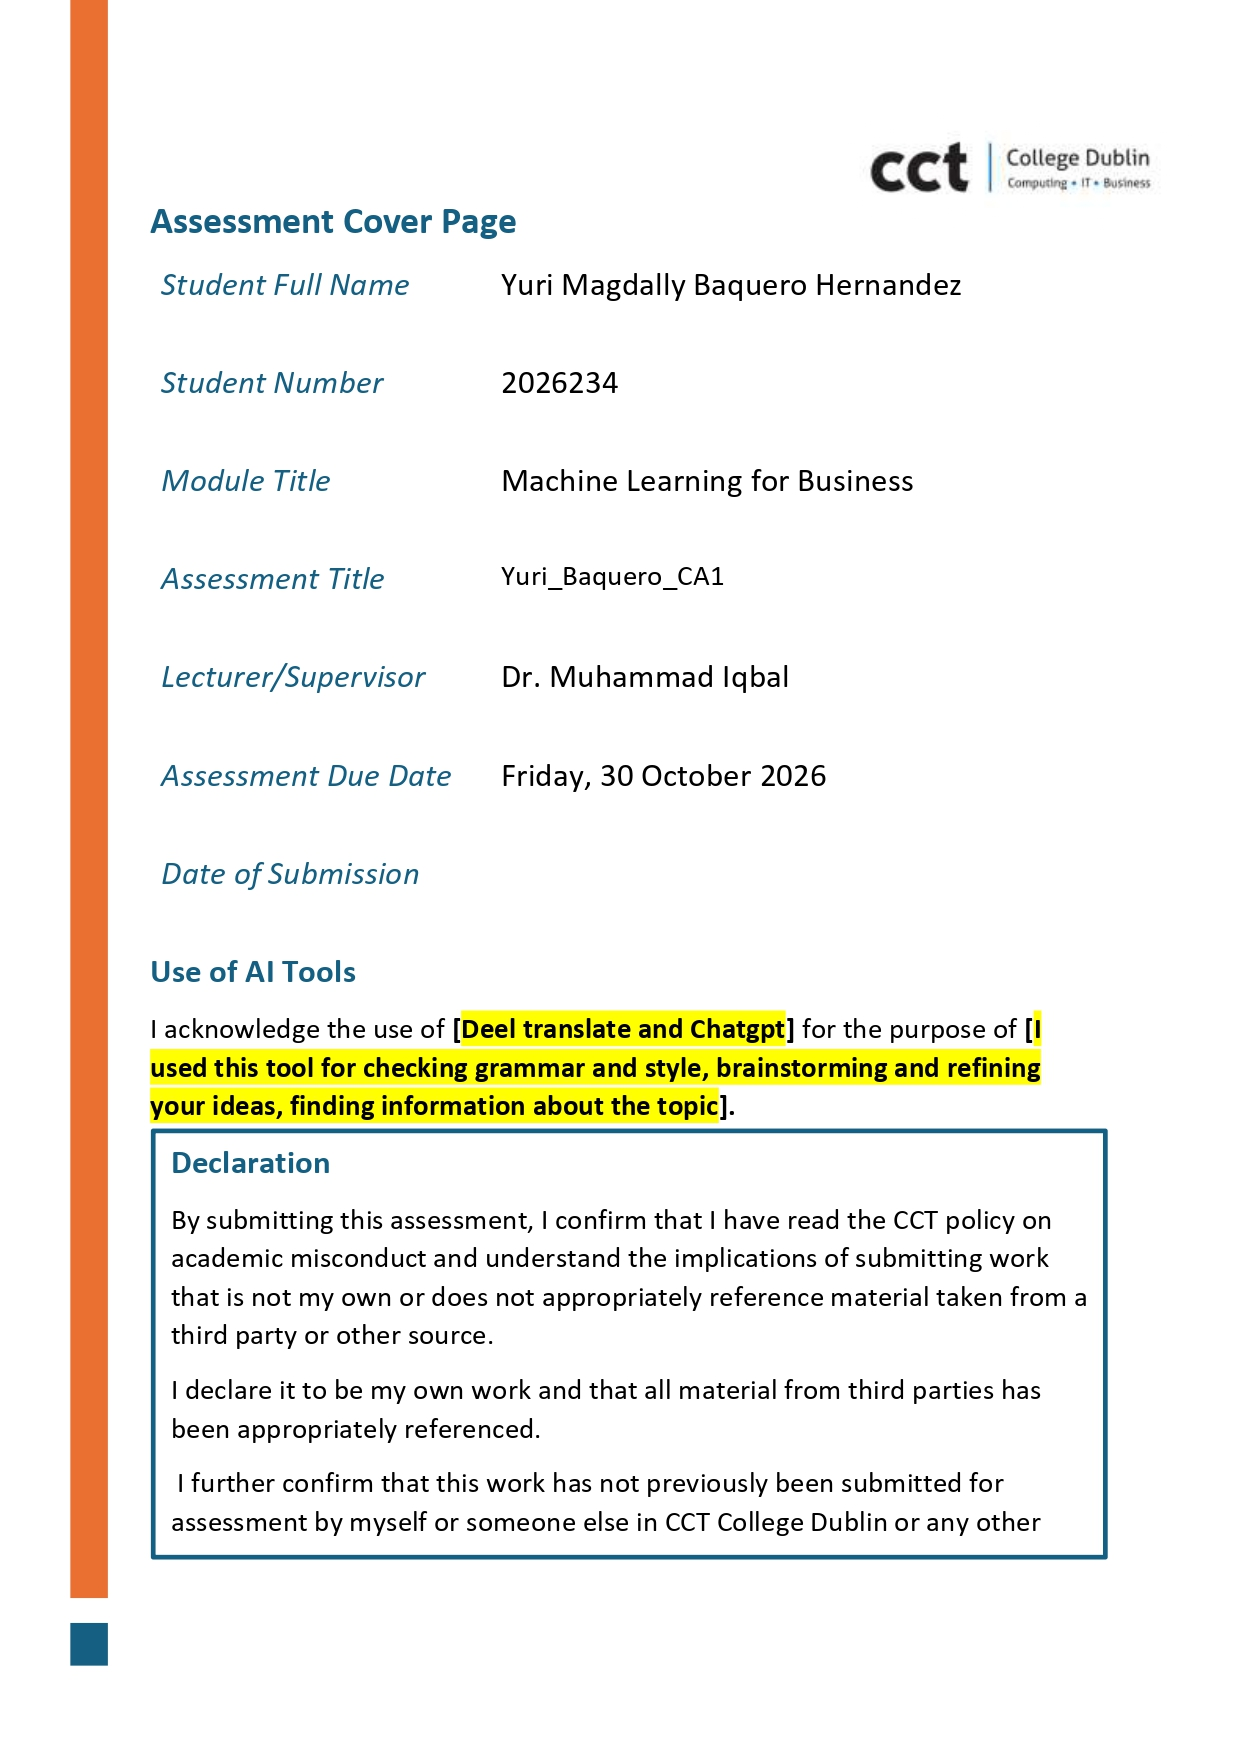

### <b>Description of Assessment Task

Students are advised to review and adhere to the submission requirements documented after the assessment task. 

This is an individual Assessment using the PYTHON programming language. Develop and deploy unsupervised machine learning models in any one of the following areas only and analyse the results.

●	Transport

●	Housing and Zoning

●	Stock market dataset (only from last 10 years) from only website: https://finance.yahoo.com/quote/CSV/history/

The dataset should have a decent number of rows and columns, such as minimum 7 columns (for example, type of variables may be categorical, continuous, and discrete) after cleaning to justify the use of the machine learning modelling approach. The type of question(s) that you should formulate for the Assessment will depend on the chosen domain of the dataset as mentioned above. (Note: No marks will be awarded if the dataset is not based on the above-mentioned guidelines.)
Assessment questions could be: (this is a small, suggested, sample of questions, other questions may be more appropriate to your Assessment)

●	How to measure similarity or dissimilarity between different clusters?

●	Which clustering solution do you prefer, and why? 

●	How to analyse and investigate an inflation rate for a specific product from the provided time series dataset?  

You will present their findings and defend the results in the form of a poster presentation. Your poster should capture the following aspects that are relevant to your Assessment investigations. All practical implementations are carried in the Jupyter notebook (Note: The code in the form of Python files will not be accepted.)

#### i.

A precise introduction, motivation, description of problem domain, Assessment objectives and the rationale for the chosen dataset in the above-mentioned areas. 

#### ii. 

Which clustering algorithms would you consider for segmentation, and why? Implement the solutions and discuss the differences between silhouette score and Davies-Bouldin index in the context of clustering. Compare the results obtained from any two clustering algorithms from your own chosen dataset.

#### iii.

Implement your solutions and discuss what insights can you derive from the initial exploration of the time series data based on the provided topics? Describe any trends, seasonality, or anomalies observed. How did you determine the appropriate parameters (p, d, q) for the ARIMA/ SARIMA model. Evaluate the performance of the ARIMA/ SARIMA model in forecasting future values, highlighting any strengths and limitations based on your chosen dataset.

#### iv.

Interpret and justify the results based on the problem specification or Assessment objectives by using suitable visualizations. Comments and description of Python code, conclusions of the Assessment should be specified in the poster as well as in the Jupyter notebook. Citations and references should follow the Harvard style. You are required to record a video presentation to explain and justify your poster presentation and the code in the Jupyter Notebook. The video should not exceed 5 minutes in duration, and the use of AI-generated voices or agents is not permitted. The format of video recording is mentioned below
  
#### Note:
You may choose two different datasets for task (ii) or task (iii) separately or one dataset for both tasks based on your justification for this Assessment.

### <b>Loading the dataset from yahoo finance
To bring the dataset that it has all information for this analysis.  The explanation for function pd.read_xlsx says Wes McKinney (ed.) (2017,pp.81-82) about it

In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

In [3]:
import yfinance as yf

# Define the ticker symbol for Fondo_Bursátil_iShares_MSCI_COLCAP (ICOLCAP.CL)
# For example, https://finance.yahoo.com/quote/%5EGSPC/history/?period1=1569174385&period2=1727027123
ticker_symbol = "ICOLCAP.CL"

start_date = "2016-09-30"
end_date = "2026-10-01"
# Download historical data (adjust the period as needed, e.g., '1mo', '1y', 'max')
data = yf.download(ticker_symbol,
                   start= start_date,
                   end = end_date,
                   auto_adjust=False)  # 'max' for maximum data, adjust as needed

# Save the data to a CSV file
data.to_csv('Fondo_Bursátil_iShares_MSCI_COLCAP.csv')

print("Data downloaded and saved as Fondo_Bursátil_iShares_MSCI_COLCAP.csv")

[*********************100%***********************]  1 of 1 completed

Data downloaded and saved as Fondo_Bursátil_iShares_MSCI_COLCAP.csv


#### ICOLCAP.CL
Fondo Bursátil iShares MSCI COLCAP is define (Blackrock, no date), It is the ticker symbol (on platforms such as Yahoo Finance) for the iShares MSCI COLCAP, an exchange-traded fund (ETF) managed by BlackRock.

#### Key features

#### • What it is:
Colcap is define (wikipedia, no date), It is an investment fund that tracks and replicates the performance of the MSCI COLCAP, the benchmark stock market index comprising the most liquid and largest-capitalisation shares on the Bolsa de Valores de Colombia (BVC).
#### • Diversification:
The ETF is define (Blackrock, no date), It is the rather than buying shares in a single company (such as a bank or an oil company), the ETF allows you to invest in a basket comprising several of Colombia’s leading companies in sectors such as finance, energy and utilities.
#### • How it works:
The charecteristic are (Davivienda Corredores, no date), traded on the stock market in a similar way to an individual share, making it accessible to investors seeking exposure to the Colombian market with less operational complexity and lower fees.

In [4]:
df_ICOLCAP_CL = pd.read_csv("Fondo_Bursátil_iShares_MSCI_COLCAP.csv")

### <b>Overview of the dataset

To know all observations and features that the dataset has. Because it will be that is going to be used. It is mean to read and observe the data from the file xlsx in this case. Wes McKinney (ed.) (2017,p.129) explains about the use of funtion how df.head.

In [5]:
df_ICOLCAP_CL.head()

,Price,Adj Close,Close,High,Low,Open,Volume
0,Ticker,ICOLCAP.CL,ICOLCAP.CL,ICOLCAP.CL,ICOLCAP.CL,ICOLCAP.CL,ICOLCAP.CL
1,Date,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-09-30,9253.0634765625,13652.0,13680.0,13652.0,13680.0,27000
3,2016-10-03,9129.703125,13470.0,13470.0,13408.0,13450.0,391375
4,2016-10-04,9155.4580078125,13508.0,13508.0,13450.0,13470.0,60507


In [6]:
df_ICOLCAP_CL.tail()

,Price,Adj Close,Close,High,Low,Open,Volume
2403,2026-09-24,25668.708984375,25824.5,25935.0,25821.0,25935.0,464762
2404,2026-09-25,25690.080078125,25846.0,25850.5,25693.5,25770.5,437432
2405,2026-09-28,25517.626953125,25672.5,25950.0,25595.0,25846.0,741721
2406,2026-09-29,25512.16015625,25667.0,26000.0,25610.0,26000.0,218710
2407,2026-09-30,25387.5,25387.5,25540.5,25379.0,25540.5,131357


The dataset has two non-data rows added by Yahoo Finance, this case is neccesary to remove them

In [7]:
df_ICOLCAP_CL = df_ICOLCAP_CL.iloc[2:].reset_index(drop=True)

In [8]:
df_ICOLCAP_CL.head()

,Price,Adj Close,Close,High,Low,Open,Volume
0,2016-09-30,9253.0634765625,13652.0,13680.0,13652.0,13680.0,27000
1,2016-10-03,9129.703125,13470.0,13470.0,13408.0,13450.0,391375
2,2016-10-04,9155.4580078125,13508.0,13508.0,13450.0,13470.0,60507
3,2016-10-05,9155.4580078125,13508.0,13508.0,13508.0,13508.0,0
4,2016-10-06,9217.8154296875,13600.0,13600.0,13580.0,13581.0,494132


### <b>Characterisation of the dataset

To get the description and details from the dataset. Understanding the range and distribution, also the min,max,mean, median, and checking if the data is dirty. This function is using to show continuous variables. I took the explanation for function df.describe from the explains Wes McKinney (ed.) (2017,pp.160, 297) about it.

In [9]:
df_ICOLCAP_CL.describe().round(2)

,Price,Adj Close,Close,High,Low,Open,Volume
count,2406,2406,2406,2406,2406,2406,2406
unique,2406,2234,1883,1943,1904,1910,1979
top,2016-09-30,9395.390625,13720.0,11400.0,13770.0,13800.0,0
freq,1,4,7,7,8,9,409


I am going to check the types of dataset because the features in this dataset are integer, float and object. I took the explanation for function df.dtypes from talks Wes McKinney (ed.) (2017,pp.88, 92, 318) about it.

In [10]:
df_ICOLCAP_CL.dtypes

Price        object
Adj Close    object
Close        object
High         object
Low          object
Open         object
Volume       object
dtype: object

To find out how big my data set. It is mean, The dataset has 2408 rows/observation and to has 7 columns/variables or features. I took the explanation for function df.shape from Wes McKinney (ed.) (2017,pp.88, 89, 453) talks about it.

In [11]:
df_ICOLCAP_CL.shape

(2406, 7)

Now, I need to know which dataset I will be working with and what It contains so that I can prepare it. How long the data is and undertanding columns type. It is dtypes: float64(10), object(3) I took the explanation for function df.info where explains Wes McKinney (ed.) (2017,p.406) about it.

In [12]:
df_ICOLCAP_CL.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2406 entries, 0 to 2405
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Price      2406 non-null   object
 1   Adj Close  2406 non-null   object
 2   Close      2406 non-null   object
 3   High       2406 non-null   object
 4   Low        2406 non-null   object
 5   Open       2406 non-null   object
 6   Volume     2406 non-null   object
dtypes: object(7)
memory usage: 131.7+ KB


I need to know how much missing values has the dataset.
I took the explanation for function df.isnull where Wes McKinney (ed.) (2017,pp.126, 192) talks about it.

In [13]:
df_ICOLCAP_CL.isnull().sum()

Price        0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

I am going to convert the columns to the correct data type; in other words, the price column actually contains dates, so it will be converted to a date

In the characterisation of the dataset, after the above process I identified the following finding:

Size: The dataset contains variables numerical and categorical as Dtypes: dtypes: object(7) memory usage: 131.8+ KB.

Number of attributes: The data set contains 7 columns/variables or features.

It has/does not have missing values: The dataset has 6 missing values in total.

Number of observations: The data set contains 2408 rows/observation.

### <b>Verification of the duplicate rows
 
The duplicate observations could frequently cause confusion in data analysis. For that reason I am going to check if the dataset has duplicate observations then I am going to remove them.
I took the explanation for function df.duplicated where Wes McKinney (ed.) (2017,p.197) talks about it.

In [14]:
duplicate_rows_df = df_ICOLCAP_CL[df_ICOLCAP_CL.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (0, 7)


The dataset does not have any duplicated row.

## References
* <p>https://finance.yahoo.com/</p>

* Blackrock:(no date). "Fondo Bursátil iShares MSCI COLCAP". Available at: https://www.blackrock.com/co/productos/251708/ishares-fondo-burstil-ishares-colcap-fund (Accessed: 07 October 2026)

* wikipedia: (no date). "Colcap".Available at: http://es.wikipedia.org/wiki/Colcap (Accessed: 07 October 2026)

* Blackrock:(no date). "EL ETF QUE INVIERTE EN LAS EMPRESAS MÁS IMPORTANTES DE COLOMBIA". Available at: https://www.blackrock.com/co/estrategias/invierte-en-colombia (Accessed: 07 October 2026)

* Davivienda Corredores (no date). "Características ETFs". Available at: http://daviviendacorredores.com/intermediacion/etfs (Accessed: 07 October 2026)